# Broadband flow
$$p(z | x) \approx q_\phi(z | x)$$
Flow to infer redshift given broadband photometry. 
The flow is trained on spectroscopic redshift and broadband LSST-like photometry $x$ (CFHT u + HSC grizy degraded to match LSST noise levels)

In [19]:
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
# - nflows - 
from nflows.flows.base import Flow
from nflows.distributions.normal import StandardNormal
from nflows.transforms.base import CompositeTransform
from nflows.transforms.autoregressive import MaskedPiecewiseRationalQuadraticAutoregressiveTransform

In [9]:
seed = 20261024

In [2]:
plt.rcParams.update(
    {
        'font.family': 'serif',
        'font.size': 11,
        'axes.linewidth': 1.5,
        'xtick.major.size': 5,
        'ytick.major.size': 5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
        'legend.frameon': False,
    }
)

## 2. Load the data and preserve the spatial split
Fluxes and errors are in microJy, ordered u, g, r, i, z, y, with shape (N, 6).
`native_flux` is the deep measurement; `sigma_added` is the extra noise standard
deviation needed for the target depth. The saved `flux` is one fixed degraded
realization used for validation and testing. We do not add noise to it again.
The split is spatial: 0 = training, 1 = validation, 2 = test.

In [5]:
keys = [
    'id',
    'native_flux',
    'flux',
    'fluxerr',
    'sigma_added',
    'zspec',
    'has_specz',
    'split',
    'imag',
    'cell',
]

with np.load('../data/parent.npz') as f:
    data = {key: f[key] for key in keys}

assert data['flux'].shape == data['fluxerr'].shape == (len(data['id']), 6)
assert np.isfinite(data['flux']).all() and np.isfinite(data['native_flux']).all()
assert np.isfinite(data['fluxerr']).all() and (data['fluxerr'] > 0).all()
assert np.isfinite(data['sigma_added']).all() and (data['sigma_added'] >= 0).all()
assert len(np.unique(data['id'])) == len(data['id'])
for a, b in [(0, 1), (0, 2), (1, 2)]:
    assert not np.intersect1d(
        data['cell'][data['split'] == a], data['cell'][data['split'] == b]
    ).size
spec = data['has_specz']
assert np.all((data['zspec'][spec] > 0) & (data['zspec'][spec] < 10))

## 3. Normalize the broadband photometry and uncertainties

Each context has 12 features: six asinh magnitude features (defined for negative
fluxes) and six log errors. Match `train_flows.py`: estimate means and scales
from the **full photometric training split**, without using any redshift labels.
Both flow demos use this same normalization, even though their labeled samples differ.

In [6]:
def raw_features(flux, err):
    # Asinh magnitudes remain defined for negative fluxes and nondetections.
    # Log errors let the flow distinguish measurements with different precision.
    soft = 0.02  # microJy; fixed and independent of labels
    lupt = 23.9 - (2.5 / np.log(10)) * (np.arcsinh(flux / (2 * soft)) + np.log(soft))
    return np.c_[lupt, np.log(np.maximum(err, 1e-7) / soft)].astype(np.float32)

phot_train = (data['split'] == 0) # training data
features = raw_features(data['native_flux'][phot_train], data['fluxerr'][phot_train])
mean = features.mean(axis=0)
scale = np.maximum(features.std(axis=0), 0.1)

## 4. Select training and validation
Select a fixed subset of up to 4,096 validation galaxies using the training seed.
Fixed validation photometry and labels let us compare losses across epochs.
The held-out test set never selects an epoch or a hyperparameter.

In [10]:
train = np.flatnonzero((data['split'] == 0) & np.isfinite(data['zspec']))
valid = np.flatnonzero((data['split'] == 1) & np.isfinite(data['zspec']))

rng = np.random.default_rng(seed)
vi = rng.choice(valid, min(len(valid), 4096), replace=False)
vy = data['zspec'][vi].astype(np.float32)
print(f'Training: {len(train):,}; validation: {len(valid):,} galaxies')
print(f'Fixed validation labels: {len(vy):,} secure redshifts')

Training: 22,604; validation: 4,803 galaxies
Fixed validation labels: 4,096 secure redshifts


## 5. Initialize the flow and optimizer

For training the flow we'll transform $z$ to $t$, a scaled-logit. 

In [14]:
def z_to_t(z):
    # Map the finite COSMOS support (0, 10) to the real line with a scaled logit.
    # Clipping avoids divergent logits at the grid endpoints.
    z = torch.clamp(z, 1e-5, 10 - 1e-5)
    return (torch.log(z / (10 - z)) + 2.2) / 1.1

def t_to_z(t):
    # Invert the redshift logit to return predictions in physical redshift units.
    return 10 * torch.sigmoid(t * 1.1 - 2.2)

def context(flux, err, mean, scale):
    # Apply training-only feature scaling; clipping limits extreme input values.
    return torch.from_numpy(np.clip((raw_features(flux, err) - mean) / scale, -12, 12).astype(np.float32))

vx = context(data['flux'][vi], data['fluxerr'][vi], mean, scale)
vt = z_to_t(torch.from_numpy(vy[:, None]))

In [12]:
torch.manual_seed(seed)

def make_flow(context_features=12):
    # Two conditional spline transforms map redshift to a standard normal.
    # The context comprises six broadband flux features and six error features.
    transforms = [
        MaskedPiecewiseRationalQuadraticAutoregressiveTransform(
            features=1,
            hidden_features=64,
            context_features=context_features,
            num_bins=16,
            tails='linear',
            tail_bound=5.0,
            num_blocks=2,
            dropout_probability=0.0,
            use_batch_norm=False,
        )
        for _ in range(2)
    ]
    return Flow(CompositeTransform(transforms), StandardNormal([1]))

model = make_flow()
opt = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

Trainable parameters: 44,638


## 6. Train, validate, and retain the best epoch

The loop follows `_fit_flow` in `train_flows.py`. Every batch starts from native
fluxes and draws only the missing noise variance. It uses batches of 512,
gradient clipping at 5, learning-rate reduction after a validation plateau,
and early stopping after eight epochs without an improvement of at least 1e-4.
The validation loss below is a density in transformed t, not a redshift-space score.

In [20]:
best = float('inf')
best_state = None
bad = 0
step = 0
max_steps = 20000

history = []
for epoch in range(200):
    model.train()
    rng.shuffle(train)
    losses = []
    for pos in range(0, len(train), 512):
        idx = train[pos : pos + 512]
        noise = rng.normal(size=(len(idx), 6)).astype(np.float32)
        xflux = data['native_flux'][idx] + noise * data['sigma_added'][idx]
        x = context(xflux, data['fluxerr'][idx], mean, scale)
        z = data['zspec'][idx].astype(np.float32)
        target = z_to_t(torch.from_numpy(z[:, None]))

        opt.zero_grad(set_to_none=True)
        loss = -model.log_prob(target, context=x).mean()
        if not torch.isfinite(loss):
            raise RuntimeError('Nonfinite training loss')
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()
        losses.append(float(loss.detach()))
        step += 1
        if step >= max_steps:
            break

    model.eval()
    with torch.no_grad():
        vals = [
            -model.log_prob(vt[p : p + 1024], context=vx[p : p + 1024]).sum().item()
            for p in range(0, len(vt), 1024)
        ]
        val = sum(vals) / len(vt)
    scheduler.step(val)
    history.append(
        {
            'epoch': epoch + 1,
            'step': step,
            'train_loss': float(np.mean(losses)),
            'validation_loss': val,
        }
    )
    print(f'Epoch {epoch + 1}; step {step}; train {np.mean(losses):.4f}; val {val:.4f}')
    if val < best - 1e-4:
        best = val
        best_state = copy.deepcopy(model.state_dict())
        bad = 0
    else:
        bad += 1
    if bad >= 8 or step >= max_steps:
        break

assert best_state is not None
model.load_state_dict(best_state)
model.eval()
print(f'Best validation loss: {best:.4f}')

Epoch 1; step 45; train 0.0584; val 0.0738
Epoch 2; step 90; train -0.0453; val -0.1565
Epoch 3; step 135; train -0.1264; val -0.1682
Epoch 4; step 180; train -0.1765; val -0.2880
Epoch 5; step 225; train -0.2303; val -0.0627
Epoch 6; step 270; train -0.2559; val -0.3935
Epoch 7; step 315; train -0.3572; val -0.1601
Epoch 8; step 360; train -0.3683; val -0.4952
Epoch 9; step 405; train -0.4496; val -0.4891
Epoch 10; step 450; train -0.5103; val -0.4682
Epoch 11; step 495; train -0.5028; val -0.5638
Epoch 12; step 540; train -0.5500; val -0.2925
Epoch 13; step 585; train -0.5816; val -0.6341
Epoch 14; step 630; train -0.6596; val -0.6260
Epoch 15; step 675; train -0.5951; val -0.4833
Epoch 16; step 720; train -0.5920; val -0.6964
Epoch 17; step 765; train -0.5959; val -0.4897
Epoch 18; step 810; train -0.5900; val -0.6096
Epoch 19; step 855; train -0.6452; val -0.7109
Epoch 20; step 900; train -0.6542; val -0.6475
Epoch 21; step 945; train -0.6613; val -0.7250
Epoch 22; step 990; train 

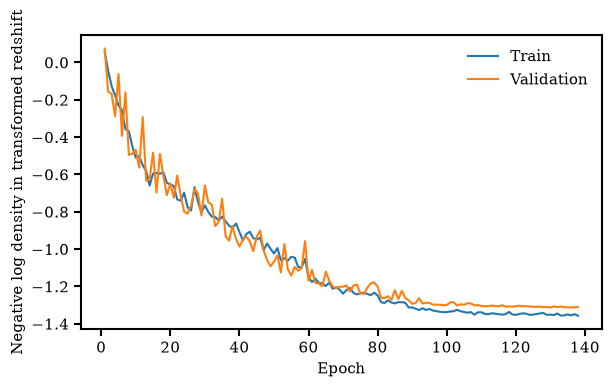

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
ax.plot([row['epoch'] for row in history], [row['train_loss'] for row in history], label='Train')
ax.plot(
    [row['epoch'] for row in history],
    [row['validation_loss'] for row in history],
    label='Validation',
)
ax.set(xlabel='Epoch', ylabel='Negative log density in transformed redshift')
ax.legend()
plt.show()

## 7. Apply flow to test photometry
Apply it to the **full photometric test split**, including galaxies without
spectroscopy. We only restrict to secure spectra later when evaluating accuracy.

In [23]:
@torch.no_grad()
def predict_quantiles(model, flux, err, mean, scale, batch_size=512):
    # Return five redshift quantiles for each six-band flux/error row.
    probs = torch.tensor([0.025, 0.16, 0.5, 0.84, 0.975])
    normal_q = torch.distributions.Normal(0.0, 1.0).icdf(probs)
    prediction = []
    for start in range(0, len(flux), batch_size):
        x = context(flux[start : start + batch_size], err[start : start + batch_size], mean, scale)
        t, _ = model._transform.inverse(
            normal_q.repeat(len(x)).reshape(-1, 1),
            context=x.repeat_interleave(5, dim=0),
        )
        prediction.append(t_to_z(t).reshape(len(x), 5).numpy())
    return np.concatenate(prediction)

phot_test = np.flatnonzero(data['split'] == 2)
q_all = predict_quantiles(model, data['flux'][phot_test], data['fluxerr'][phot_test], mean, scale)
print(f'Predicted {len(phot_test):,} test galaxies without using redshift labels')

Predicted 26,635 test galaxies without using redshift labels


## 8. Evaluate flow where independent test spectroscopy is available

In [28]:
scored = data['has_specz'][phot_test]
test = phot_test[scored]
ztest = data['zspec'][test]
q = q_all[scored]

[(0.0, 5.0),
 (0.0, 5.0),
 Text(0.5, 0, '$z_{\\mathrm{spec}}$'),
 Text(0, 0.5, 'Median $z$')]

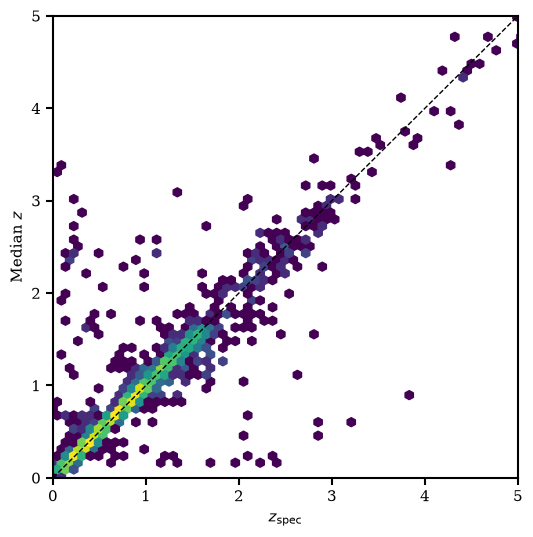

In [29]:
fig = plt.figure(figsize=(6,6))
sub = fig.add_subplot(111)
sub.hexbin(ztest, q[:, 2], gridsize=60, bins='log', mincnt=1, cmap='viridis')
sub.plot([0, 5], [0, 5], 'k--', lw=1)
sub.set(xlim=(0, 5), ylim=(0, 5), xlabel=r'$z_{\mathrm{spec}}$', ylabel=r'Median $z$')

In [33]:
@torch.no_grad()
def log_prob_z(model, z, ctx):
    z = torch.as_tensor(z, dtype=torch.float32).reshape(-1, 1)
    w = z_to_t(z)
    # The flow density is in transformed t; add log|dt/dz| to obtain p(z | x).
    jac = np.log(10) - torch.log(z) - torch.log(10 - z) - np.log(1.1)
    return model.log_prob(w, context=ctx) + jac[:, 0]

@torch.no_grad()
def posterior_summary(model, ctx, zspec):
    # Invert standard-normal quantiles rather than estimate intervals from samples.
    probs = torch.tensor([0.025, 0.16, 0.5, 0.84, 0.975])
    noise = torch.distributions.Normal(0.0, 1.0).icdf(probs)
    quant = []
    pit = []
    nll = []
    for start in range(0, len(ctx), 512):
        x = ctx[start : start + 512]
        n = len(x)
        q, _ = model._transform.inverse(
            noise.repeat(n).reshape(-1, 1), context=x.repeat_interleave(5, dim=0)
        )
        quant.append(t_to_z(q).reshape(n, 5).numpy())
        z = torch.tensor(zspec[start : start + 512], dtype=torch.float32).reshape(-1, 1)
        # The base-normal CDF gives the posterior rank (PIT) of the true spec-z.
        u, _ = model._transform(z_to_t(z), context=x)
        pit.append((0.5 * (1 + torch.erf(u[:, 0] / np.sqrt(2)))).numpy())
        nll.append((-log_prob_z(model, z, x)).numpy())
    return np.concatenate(quant), np.concatenate(pit), np.concatenate(nll)

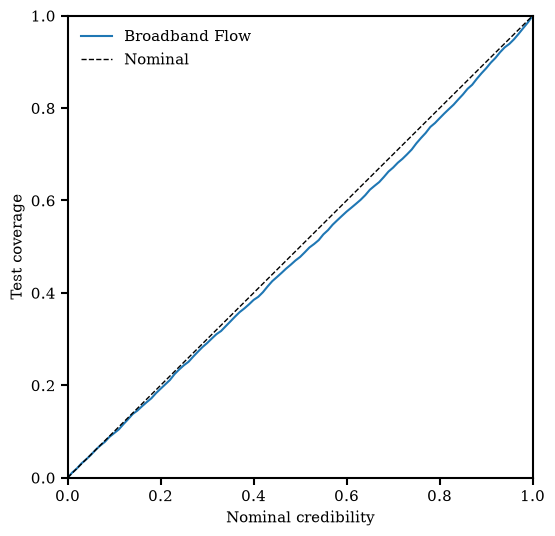

In [34]:
q_check, pit, nll = posterior_summary(model, ctx, ztest)


credibility = np.linspace(0, 1, 101)
rank = np.abs(2 * pit - 1)
curve = np.array([(rank <= level).mean() for level in credibility])
curve[0], curve[-1] = 0, 1

fig = plt.figure(figsize=(6,6))
sub = fig.add_subplot(111)
sub.plot(credibility, curve, label='Broadband Flow')
sub.plot([0, 1], [0, 1], 'k--', lw=1, label='Nominal')
sub.set(xlim=(0, 1), ylim=(0, 1), xlabel='Nominal credibility', ylabel='Test coverage')
sub.legend()
plt.show()

Example PDFs below use `log_prob_z`, including the redshift Jacobian.
Examples span the spectroscopic test sample's native i-band magnitudes.
Dashed lines show test spectroscopy for evaluation only.

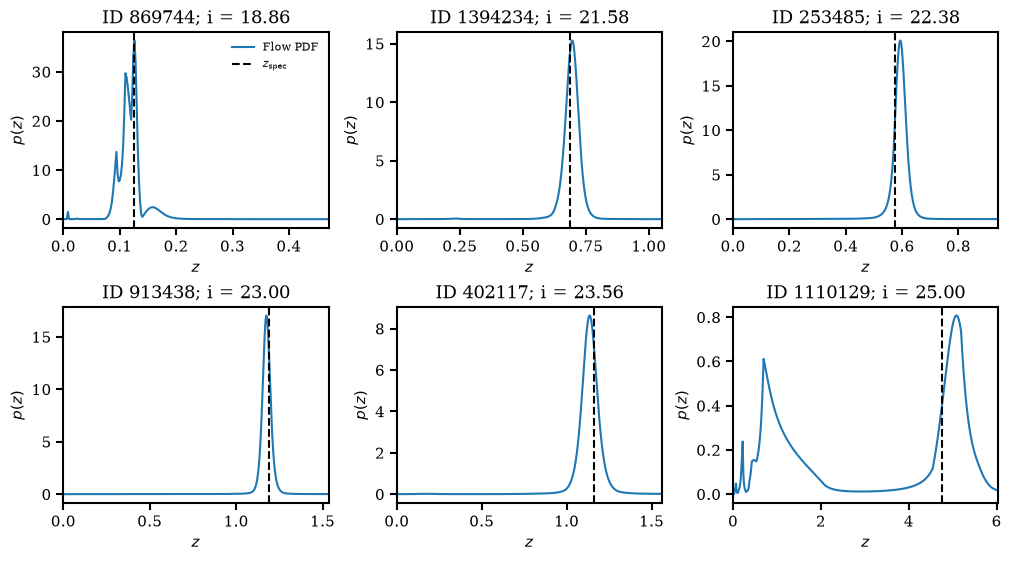

In [35]:
order = np.argsort(data['imag'][test])
examples = order[np.linspace(0, len(order) - 1, 6, dtype=int)]
zgrid = np.linspace(1e-4, 10 - 1e-4, 5001, dtype=np.float32)
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, j in zip(axes.flat, examples):
    x = ctx[j : j + 1].repeat(len(zgrid), 1)
    pdf = np.exp(log_prob_z(model, zgrid, x).numpy())
    assert np.isfinite(pdf).all() and (pdf >= 0).all()
    ax.plot(zgrid, pdf, label='Flow PDF')
    ax.axvline(ztest[j], color='k', ls='--', label=r'$z_{\mathrm{spec}}$')
    ax.set(xlim=(0, min(10, max(q[j, 4], ztest[j]) + 0.3)), xlabel=r'$z$', ylabel=r'$p(z)$')
    ax.set_title(f'ID {data["id"][test[j]]}; i = {data["imag"][test[j]]:.2f}')
axes.flat[0].legend(fontsize=8)
plt.show()

## 9. Save flow and its predictions

In [40]:
checkpoint = {
    'state_dict': best_state,
    'feature_mean': mean,
    'feature_scale': scale,
    'model': 'two conditional RQS autoregressive transforms; 16 bins; hidden64; blocks2',
    'n_train': len(train),
    'n_validation': len(valid),
    'seed': seed,
}
torch.save(checkpoint, '../data/broadband_flow.pt')

prediction = {key: data[key][test] for key in ['id', 'zspec', 'imag', 'flux', 'fluxerr']}
prediction.update({'quantiles': q, 'pit': pit, 'nll': nll})
np.savez_compressed(
    '../data/broadband_flow_test_predictions.npz', **prediction)